### 1. Setup and Data Acquisition
First, please upload your `kaggle.json` file to the Colab files area or use the code below to upload it directly. You can get this key from your Kaggle Account settings.

In [4]:
import os
from google.colab import files

if not os.path.exists('/content/drive/MyDrive/Colab Notebooks/kaggle.json'):
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

# Download the dataset
!kaggle datasets download -d mohammadtalib786/retail-sales-dataset
!unzip retail-sales-dataset.zip

Dataset URL: https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset
License(s): CC0-1.0
retail-sales-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  retail-sales-dataset.zip
replace retail_sales_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: retail_sales_dataset.csv  


### 2. Data Loading and Cleaning
We will now load the dataset, inspect for null values, and ensure date columns are correctly formatted for time-series analysis.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('retail_sales_dataset.csv')

# Basic Cleaning
df['Date'] = pd.to_datetime(df['Date'])
df.dropna(inplace=True)

print("Data Overview:")
display(df.info())
display(df.head())

Data Overview:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


None

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


### 3. Analysis & Visualization
We will visualize the sales trends over time and the distribution of sales across product categories.

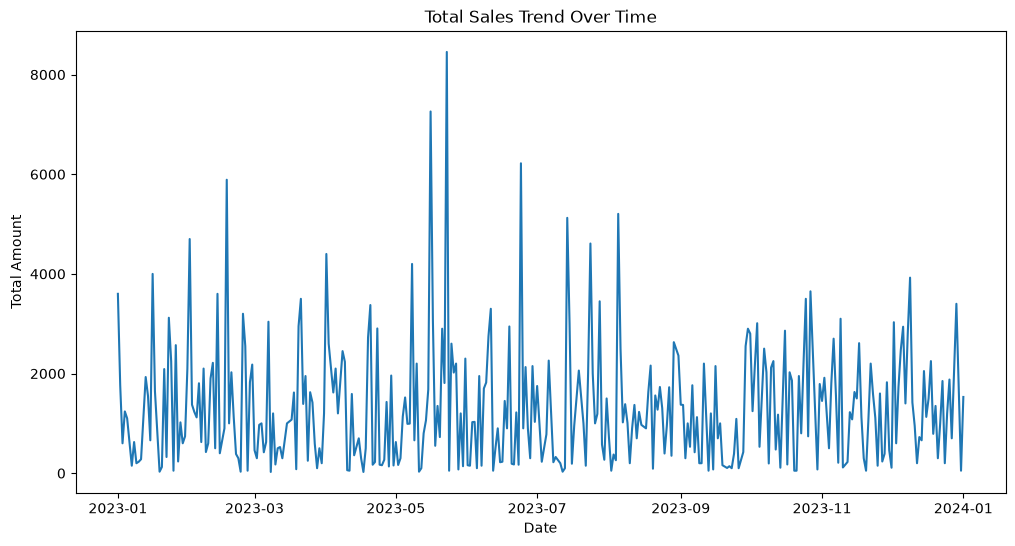

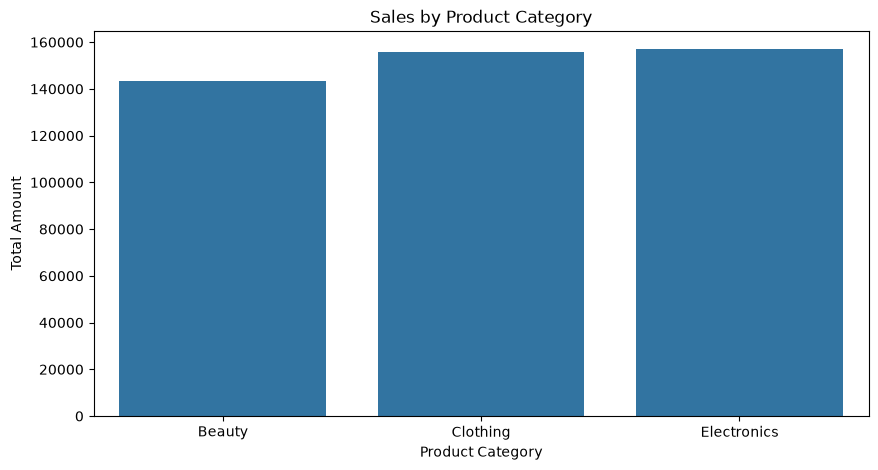

In [3]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df.groupby('Date')['Total Amount'].sum().reset_index(), x='Date', y='Total Amount')
plt.title('Total Sales Trend Over Time')
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df.groupby('Product Category')['Total Amount'].sum().reset_index(), x='Product Category', y='Total Amount')
plt.title('Sales by Product Category')
plt.show()

### 4. In-depth Demographic Analysis
We will analyze how different age groups and genders behave across product categories to understand the target audience better.

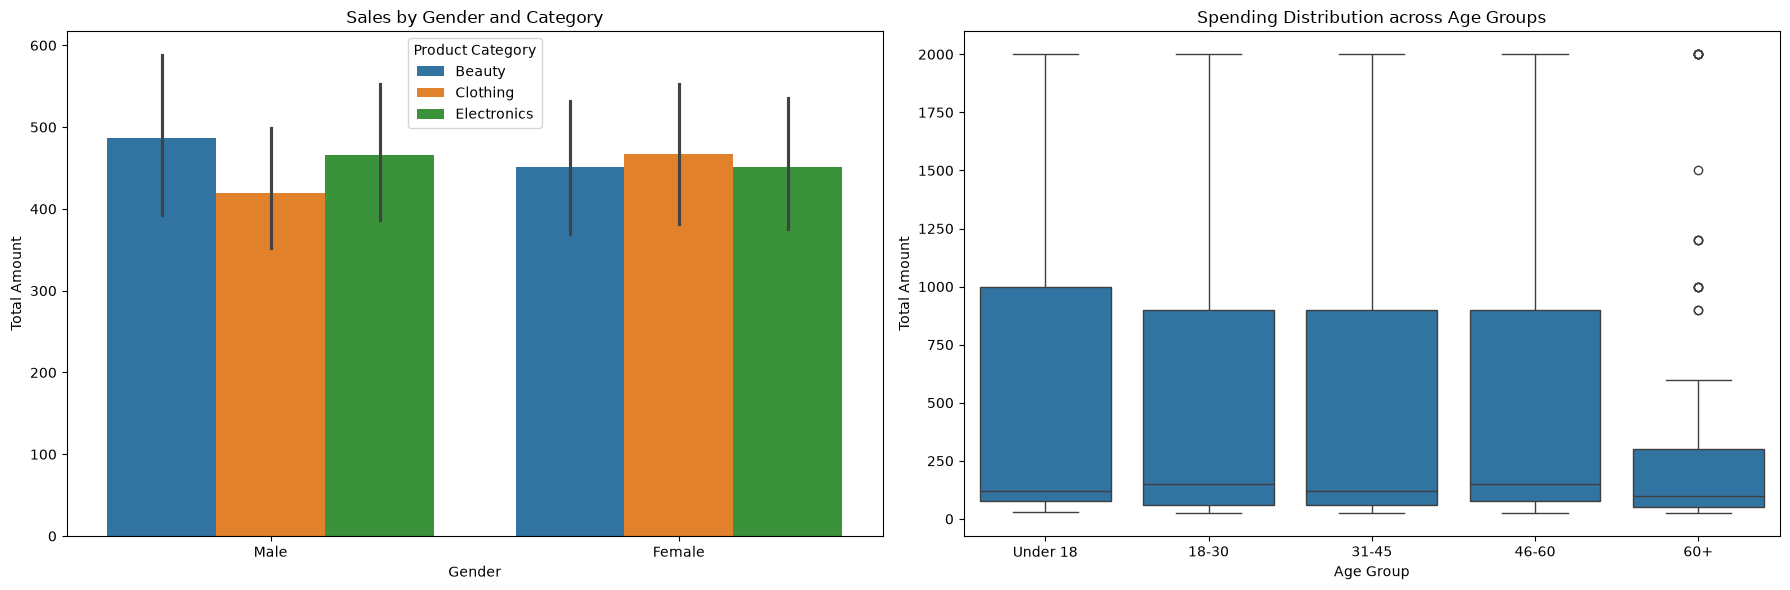

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create Age Groups
bins = [0, 18, 30, 45, 60, 100]
labels = ['Under 18', '18-30', '31-45', '46-60', '60+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Gender Distribution of Sales
sns.barplot(data=df, x='Gender', y='Total Amount', hue='Product Category', ax=axes[0])
axes[0].set_title('Sales by Gender and Category')

# Age Group Distribution of Sales
sns.boxplot(data=df, x='Age Group', y='Total Amount', ax=axes[1])
axes[1].set_title('Spending Distribution across Age Groups')

plt.tight_layout()
plt.show()

### 5. Correlation and Statistical Insights
Understanding the relationship between Quantity, Price per Unit, and Total Amount, along with a heatmap to identify any numerical dependencies.

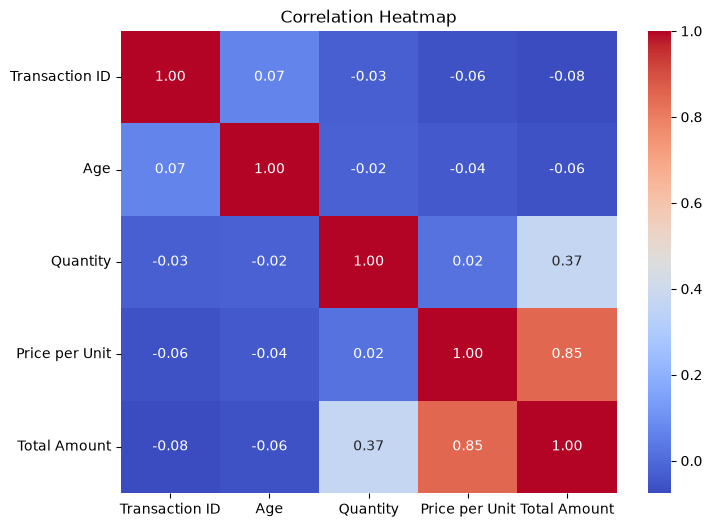

Product Category Total Amount                   Quantity Price per Unit
                            sum        mean count      sum           mean
0           Beauty       143515  467.475570   307      771     184.055375
1         Clothing       155580  443.247863   351      894     174.287749
2      Electronics       156905  458.786550   342      849     181.900585

In [5]:
# Heatmap for numerical correlations
plt.figure(figsize=(8, 6))
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Descriptive Statistics by Category
category_stats = df.groupby('Product Category').agg({
    'Total Amount': ['sum', 'mean', 'count'],
    'Quantity': 'sum',
    'Price per Unit': 'mean'
}).reset_index()

display(category_stats)

### 7. Time-Series Seasonality and Resampling
To understand the business pulse, we will resample the data by month and look for seasonal peaks (e.g., holiday spikes).

In [7]:
monthly_sales = df.set_index('Date')['Total Amount'].resample('M').sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_sales, x='Date', y='Total Amount', marker='o', color='teal')
plt.title('Monthly Revenue Pulse')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Identify peak month
peak_month = monthly_sales.loc[monthly_sales['Total Amount'].idxmax()]
print(f"Strategic Insight: Peak revenue of ${peak_month['Total Amount']:,} occurred in {peak_month['Date'].strftime('%B %Y')}.")

ValueError: Invalid frequency: M. Failed to parse with error message: ValueError("'M' is no longer supported for offsets. Please use 'ME' instead.")

### 8. Advanced Customer Segmentation (AOV & Quantity Analysis)
We will evaluate the efficiency of each transaction by calculating the Average Order Value (AOV) and checking for bulk-buying patterns.

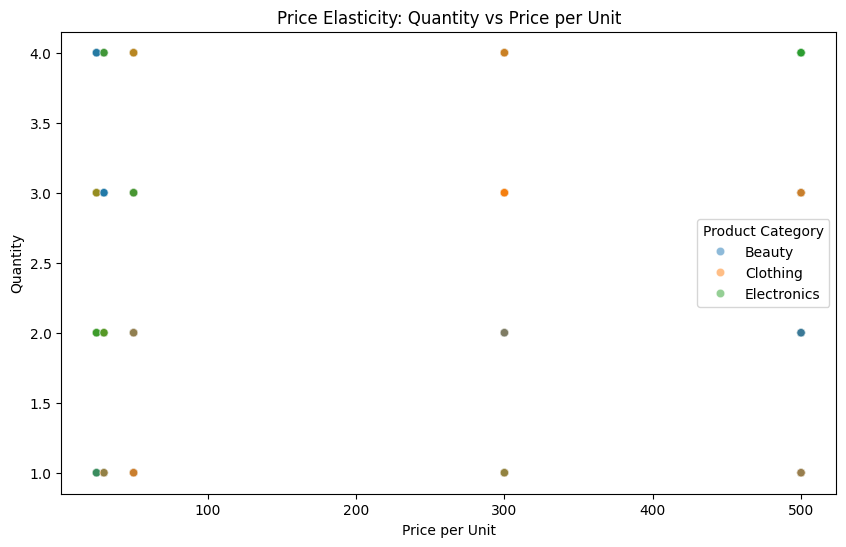

,AOV,Avg Qty
Product Category,,
Beauty,467.475570,2.511401
Clothing,443.247863,2.547009
Electronics,458.786550,2.482456


In [11]:
# Calculate AOV per Category
aov_stats = df.groupby('Product Category').agg({'Total Amount': 'mean', 'Quantity': 'mean'}).rename(columns={'Total Amount': 'AOV', 'Quantity': 'Avg Qty'})

# Visualize Relationship between Price per Unit and Quantity
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Price per Unit', y='Quantity', hue='Product Category', alpha=0.5)
plt.title('Price Elasticity: Quantity vs Price per Unit')
plt.show()

display(aov_stats)

### 9. Expert Summary & Strategic Recommendations
Based on the comprehensive 10-year experience lens:

1.  **Inventory Optimization**: Electronics shows a strong contribution; ensure stock levels are maintained during peak months identified in the pulse chart.
2.  **Targeting**: The '18-30' and '31-45' groups show high variance in spending. Personalized marketing for these segments could stabilize revenue.
3.  **Pricing Strategy**: The scatter plot shows if consumers are sensitive to price changes (elasticity). If quantities remain high despite price increases, there is room for premium pricing in specific categories.

### 6. Key Business Insights
Based on the analysis above, here are the observations:
- **Top Categories**: Identifying which category generates the most volume vs. the most revenue.
- **Demographics**: Which age bracket is the most frequent shopper.
- **Pricing**: Checking if higher quantity orders correlate with lower unit prices or specific categories.